# XGBoost

Gradient-boosted trees for predicting whether an unplanned New York hospital admission
lasts more than 7 days. Decisions are in
`docs/notes/2026-11-10-model-comparison-plan.md` and `docs/notes/2026-11-13-xgboost.md`.
The data, cohort, split, cleaning and encoder come from `analysis/common.py`, and
`analysis/baseline_model.py` walks through them.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost
from xgboost import XGBClassifier

from analysis import common

RESULTS_DIR = common.RESULTS_DIR / "xgboost"
print(f"XGBoost {xgboost.__version__}")

XGBoost 3.4.1


## Setup

The same training set, features and folds as the baseline. The recalibration set is
only used in Recalibration, where the final model predicts on it. The test set isn't used
yet.

In [2]:
train, recal, test = common.load_splits()
X, y = train[common.FEATURES], train["y"]
print(f"{len(train):,} training stays, {y.mean():.1%} stayed more than 7 days")
print(f"{len(common.FEATURES)} features")

360,000 training stays, 23.1% stayed more than 7 days
17 features


## Tuning

### The model

Boosting grows small trees one after another. It starts every stay at the overall
long-stay rate, on the log-odds scale. Each new tree is fit to the current errors, so it
finds groups of stays the model so far gets wrong in the same direction. Its output is
shrunk by the learning rate and added to every stay's score. A stay's risk is the
sigmoid of its starting score plus the sum of all the trees, the same link as logistic
regression.

Fixed settings:

- **`learning_rate = 0.1`.** It trades off against the number of trees, which is tuned.
- **`gamma = 0`, `reg_alpha = 0`, `reg_lambda = 1`,** XGBoost's defaults. Tuning them
  is worth about 0.003 AUC (Probst, Boulesteix & Bischl, 2019).
- **`n_estimators = 2000`,** a cap. The number of trees actually used is chosen by CV.
- **No `scale_pos_weight`,** since reweighting the classes would distort the risks.

The grid:

- `max_depth` in {4, 6, 8}: how complex each tree is.
- `min_child_weight` in {1, 10}: the least data a leaf may hold, like `min_samples_leaf`
  for the decision tree.
- `subsample` = `colsample_bytree` in {0.8, 1.0}: the share of rows and of columns each
  tree sees. They're tied to keep the grid small.

That's 12 settings × 5 folds = 60 fits.

In [3]:
MAX_DEPTHS = [4, 6, 8]
MIN_CHILD_WEIGHTS = [1, 10]
SUBSAMPLES = [0.8, 1.0]
MAX_TREES = 2000
SETTINGS = ["max_depth", "min_child_weight", "subsample"]


def make_model(max_depth, min_child_weight, subsample, n_estimators=MAX_TREES):
    return XGBClassifier(
        n_estimators=n_estimators,
        learning_rate=0.1,
        max_depth=max_depth,
        min_child_weight=min_child_weight,
        subsample=subsample,
        colsample_bytree=subsample,
        objective="binary:logistic",
        tree_method="hist",
        eval_metric=["auc", "rmse"],
        n_jobs=8,
        random_state=common.SEED,
    )

### Number of trees

The number of trees is tuned like the other settings, and one number is chosen for all
folds. A model with k trees is just the first k trees of a bigger fit, so each fit
grows all 2,000 trees and scores the validation fold after every tree. Averaging those
curves across the 5 folds gives the CV score of every count from 1 to 2,000 at once.

There's no per-fold early stopping. Stopping each fold where its own validation fold
peaks would let that fold both choose and grade the model, and the CV score would come
out optimistic.

XGBoost's `rmse` on `binary:logistic` is computed on the risks, so Brier = rmse². This
was checked on simulated data. The chosen model's fold scores will check it again
against `common.fold_scores`.

### Fits

`common.encode_folds` fits the encoder on each fold's training part only, and each fold
is encoded once. The one-hot matrices are made dense before fitting. XGBoost reads an
absent entry of a sparse matrix as missing rather than 0, and scoring a sparse
validation fold after every tree was twice as slow. On one fold, dense and sparse input
gave the same AUC to 5 decimals at 50 and at 200 trees.

The fits run one at a time, each on all 8 cores, since 8 dense folds at once wouldn't
fit in memory. One fit at depth 8 should take about 2 minutes, from timing 200 trees.
For each fit we save the
validation AUC and Brier after every tree, and the fit time. To recompute, delete
`results/xgboost/tuning.csv` and `tuning_curves.parquet`.

In [4]:
def dense(matrix):
    return matrix.toarray().astype(np.float32)


def fit_one(fold, max_depth, min_child_weight, subsample, n_estimators=MAX_TREES):
    """Fit one setting on one fold and score the validation part after every tree."""
    model = make_model(max_depth, min_child_weight, subsample, n_estimators)
    X_validation = dense(fold["X_validation"])
    start = time.perf_counter()
    model.fit(
        dense(fold["X_fit"]),
        fold["y_fit"],
        eval_set=[(X_validation, fold["y_validation"])],
        verbose=False,
    )
    seconds = time.perf_counter() - start
    history = model.evals_result()["validation_0"]
    curve = pd.DataFrame(
        {
            "max_depth": max_depth,
            "min_child_weight": min_child_weight,
            "subsample": subsample,
            "fold": fold["fold"],
            "trees": np.arange(1, n_estimators + 1),
            "auc": history["auc"],
            "brier": np.square(history["rmse"]),
        }
    )
    return model, X_validation, curve, seconds


def run_tuning():
    folds = common.encode_folds(X, y)
    curves, rows = [], []
    for max_depth in MAX_DEPTHS:
        for min_child_weight in MIN_CHILD_WEIGHTS:
            for subsample in SUBSAMPLES:
                for fold in folds:
                    _, _, curve, seconds = fit_one(
                        fold, max_depth, min_child_weight, subsample
                    )
                    curves.append(curve)
                    best = curve.loc[curve["auc"].idxmax()]
                    rows.append(
                        {
                            "max_depth": max_depth,
                            "min_child_weight": min_child_weight,
                            "subsample": subsample,
                            "fold": fold["fold"],
                            "fold_best_trees": int(best["trees"]),
                            "fold_best_auc": best["auc"],
                            "seconds": seconds,
                        }
                    )
                    print(
                        f"depth {max_depth}, min_child_weight {min_child_weight}, "
                        f"subsample {subsample}, fold {fold['fold']}: "
                        f"best AUC {best['auc']:.4f} at {int(best['trees'])} trees, "
                        f"{seconds:.0f}s",
                        flush=True,
                    )
    return {"tuning": pd.DataFrame(rows), "curves": pd.concat(curves, ignore_index=True)}


tuned = common.load_or_compute(
    {
        "tuning": RESULTS_DIR / "tuning.csv",
        "curves": RESULTS_DIR / "tuning_curves.parquet",
    },
    run_tuning,
)
tuning, curves = tuned["tuning"], tuned["curves"]

n_settings = len(MAX_DEPTHS) * len(MIN_CHILD_WEIGHTS) * len(SUBSAMPLES)
assert len(tuning) == n_settings * common.FOLDS.get_n_splits()
assert len(curves) == len(tuning) * MAX_TREES
print(f"{tuning['seconds'].sum() / 60:.0f} minutes of fitting in total")

Loaded saved results
93 minutes of fitting in total


### Tuning curve

Mean CV AUC and Brier across the 5 folds after every tree, for each setting. The
baseline's CV AUC and Brier, from `results/baseline_logistic/cv_scores.csv`, are the
reference.

In [5]:
mean_curves = (
    curves.groupby(SETTINGS + ["trees"])
    .agg(
        auc=("auc", "mean"),
        auc_sd=("auc", "std"),
        brier=("brier", "mean"),
        brier_sd=("brier", "std"),
    )
    .reset_index()
)

baseline_scores = pd.read_csv(common.RESULTS_DIR / "baseline_logistic" / "cv_scores.csv")
baseline_auc = baseline_scores["auc"].mean()
baseline_brier = baseline_scores["brier"].mean()
print(f"Baseline: AUC {baseline_auc:.4f}, Brier {baseline_brier:.4f}")

Baseline: AUC 0.7734, Brier 0.1447


One panel per tree depth, one line per `min_child_weight` and subsampling pair. The
dot on each line is its best tree count by mean CV AUC. The first 50 trees are left
out, since their scores are far below the rest and would squash the plot.

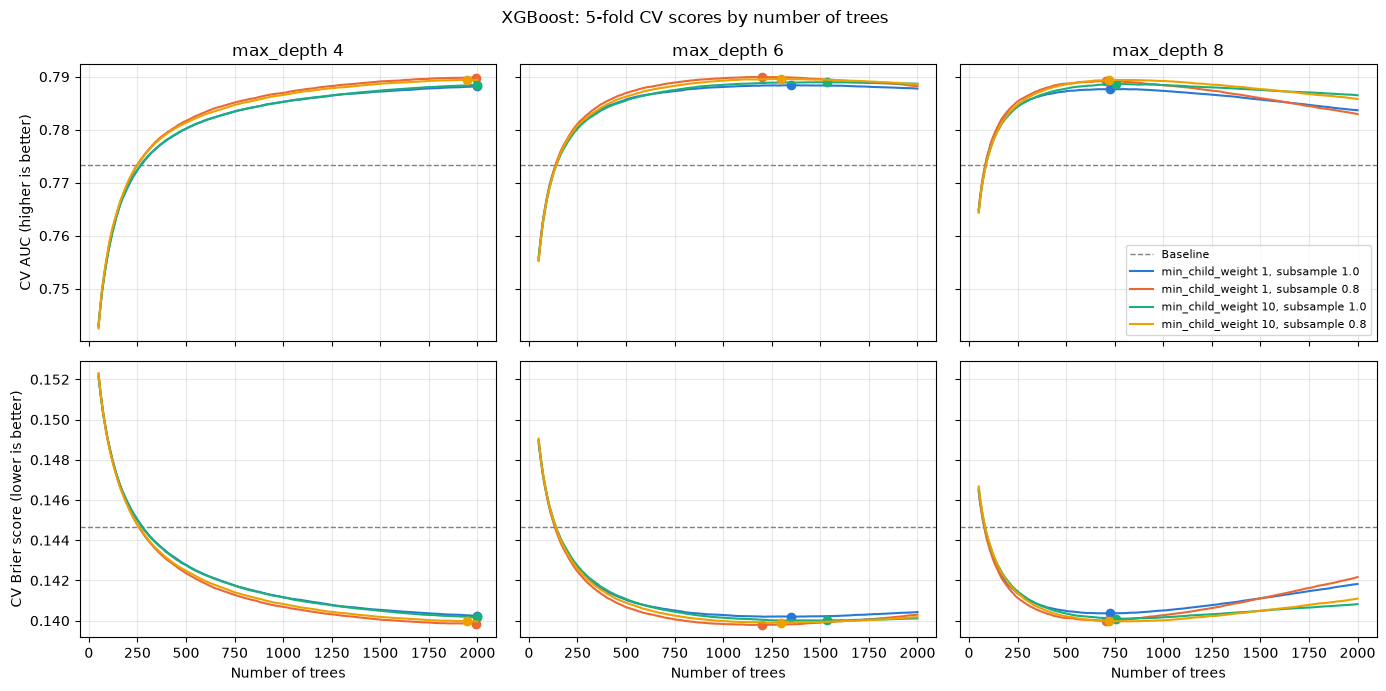

In [6]:
LINES = [
    (1, 1.0, "#2a78d6"),
    (1, 0.8, "#eb6834"),
    (10, 1.0, "#1baf7a"),
    (10, 0.8, "#eda100"),
]
FIRST_PLOTTED = 50

fig, axes = plt.subplots(2, len(MAX_DEPTHS), figsize=(14, 7), sharex=True, sharey="row")
for col, max_depth in enumerate(MAX_DEPTHS):
    for row, (score, baseline_value, label) in enumerate(
        [
            ("auc", baseline_auc, "CV AUC (higher is better)"),
            ("brier", baseline_brier, "CV Brier score (lower is better)"),
        ]
    ):
        ax = axes[row, col]
        ax.axhline(baseline_value, color="gray", linestyle="--", linewidth=1, label="Baseline")
        for min_child_weight, subsample, color in LINES:
            line = mean_curves[
                (mean_curves["max_depth"] == max_depth)
                & (mean_curves["min_child_weight"] == min_child_weight)
                & (mean_curves["subsample"] == subsample)
            ]
            best = line.loc[line["auc"].idxmax()]
            shown = line[line["trees"] >= FIRST_PLOTTED]
            ax.plot(
                shown["trees"],
                shown[score],
                color=color,
                linewidth=1.5,
                label=f"min_child_weight {min_child_weight}, subsample {subsample}",
            )
            ax.plot(best["trees"], best[score], "o", color=color, markersize=6)
        ax.grid(alpha=0.3)
        if row == 0:
            ax.set_title(f"max_depth {max_depth}")
        else:
            ax.set_xlabel("Number of trees")
        if col == 0:
            ax.set_ylabel(label)
axes[0, -1].legend(loc="lower right", fontsize=8)
fig.suptitle("XGBoost: 5-fold CV scores by number of trees")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "tuning.png", dpi=150)

### Best tree count for each setting

Each setting at its best tree count by mean CV AUC, with each score's difference from
the baseline. `fold_best_trees` is the range of the folds' own best counts, to show how
stable the choice is. It isn't used for choosing.

Darker shading is better: higher AUC, lower Brier. The best value in each shaded column
is in bold.

In [7]:
best = mean_curves.loc[mean_curves.groupby(SETTINGS)["auc"].idxmax()].copy()
fold_best = (
    tuning.groupby(SETTINGS)["fold_best_trees"]
    .agg(lambda counts: f"{counts.min()}–{counts.max()}")
    .rename("fold_best_trees")
)
best = best.merge(fold_best, on=SETTINGS)
best["auc_vs_baseline"] = best["auc"] - baseline_auc
best["brier_vs_baseline"] = best["brier"] - baseline_brier
best = best.sort_values("auc", ascending=False)
common.show_scores(
    best[
        SETTINGS
        + [
            "trees",
            "fold_best_trees",
            "auc",
            "auc_sd",
            "auc_vs_baseline",
            "brier",
            "brier_sd",
            "brier_vs_baseline",
        ]
    ],
    highlight=True,
)

max_depth,min_child_weight,subsample,trees,fold_best_trees,auc,auc_sd,auc_vs_baseline,brier,brier_sd,brier_vs_baseline
6,1,0.8,1198,1112–1292,0.79,0.002332,+0.01654,0.1398,0.0005609,-0.00488
4,1,0.8,1992,1813–2000,0.7898,0.001926,+0.01639,0.1399,0.0005024,-0.00483
6,10,0.8,1298,1235–1422,0.7896,0.00227,+0.01617,0.1399,0.0005794,-0.00478
4,10,0.8,1949,1916–1965,0.7894,0.002083,+0.01599,0.14,0.0005298,-0.00471
8,10,0.8,721,717–944,0.7894,0.002286,+0.01597,0.14,0.0005829,-0.00470
8,1,0.8,705,615–793,0.7892,0.002329,+0.01580,0.14,0.0005737,-0.00468
6,10,1,1532,1309–1869,0.789,0.002338,+0.01555,0.14,0.0006237,-0.00466
8,10,1,759,721–919,0.7886,0.002509,+0.01520,0.1401,0.0006535,-0.00458
4,10,1,2000,1914–2000,0.7885,0.002083,+0.01504,0.1402,0.0005234,-0.00451
6,1,1,1348,1074–1575,0.7884,0.002124,+0.01498,0.1402,0.0005382,-0.00448
